# Basics 2: QC, normalisation and embedding

The second of three notebooks that together run or name every public function:

1. [Reading and preparing data](basics_1_data.ipynb)
2. **QC, normalisation and embedding** (this notebook): filter cells, perturbations and genes; subsample; normalise; select variable genes; PCA, neighbours and UMAP.
3. [Effects and differential expression](basics_3_effects_tests.ipynb)

It runs on its own, on the bundled `data/Adamson_subset.h5ad` (1,716 cells, 11,630 genes, two targets and a control), in under a minute. Every step streams the matrix from disk and writes its result to a file; the table at the end lists the functions of this area.

In [1]:
import os

# Progress bars off, so the saved notebook keeps only crispyx's summary lines; tqdm
# reads this when first imported, so it is set before anything imports tqdm.
os.environ.setdefault('TQDM_DISABLE', '1')

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
DATA_PATH = ROOT / 'data' / 'Adamson_subset.h5ad'
OUTPUT_DIR = Path('tutorial_outputs') / 'basics_qc'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='IProgress not found')

import crispyx as cx
print(f'crispyx {cx.__version__}')

crispyx 0.2.10


## 1. Quality control

QC keeps cells with enough detected genes, perturbations with enough cells, and genes seen in enough cells. Each filter is a function that returns a boolean mask; a later filter takes the earlier mask, so it counts only the cells still kept.

In [2]:
cell_mask = cx.pp.filter_cells(DATA_PATH, min_genes=1000)
cell_mask = cx.pp.filter_perturbations(DATA_PATH, perturbation_column='perturbation', min_cells=50, base_mask=cell_mask)
gene_mask = cx.pp.filter_genes(DATA_PATH, min_cells=100, cell_mask=cell_mask)

[cx] pp.filter_cells: Done  1715/1716 cells kept (100%)
[cx] resolve_control_label: Inferred control label 'control'
[cx] pp.filter_perturbations: Done  3/3 perturbations kept (100%)
[cx] pp.filter_genes: Done  9238/11630 genes kept (79%)


`cx.pp.qc_summary` applies the three in one call and writes the filtered file. `cx.quality_control_summary`, used here, is the same call returning the masks and the per-cell and per-gene counts as well, which the QC plots take.

In [3]:
qc = cx.quality_control_summary(
    DATA_PATH, perturbation_column='perturbation',
    min_genes=1000, min_cells_per_perturbation=50, min_cells_per_gene=100,
    output_path=OUTPUT_DIR / 'filtered.h5ad',
)
filtered_path = qc.filtered.path
print('same masks as the three filters:', (qc.cell_mask == cell_mask).all() and (qc.gene_mask == gene_mask).all())

[cx] pp.qc_summary: Reading ../../data/Adamson_subset.h5ad
[cx] resolve_control_label: Inferred control label 'control'
[cx] pp.qc_summary: Saving → tutorial_outputs/basics_qc/filtered.h5ad
[cx] pp.qc_summary: Strategy — in-memory (0.0 GB, estimated 0.2 GB in memory)
[cx] pp.qc_summary: Done  1715/1716 cells kept (100%), 9238/11630 genes kept (79%), 3/3 perturbations kept (100%)
same masks as the three filters: True


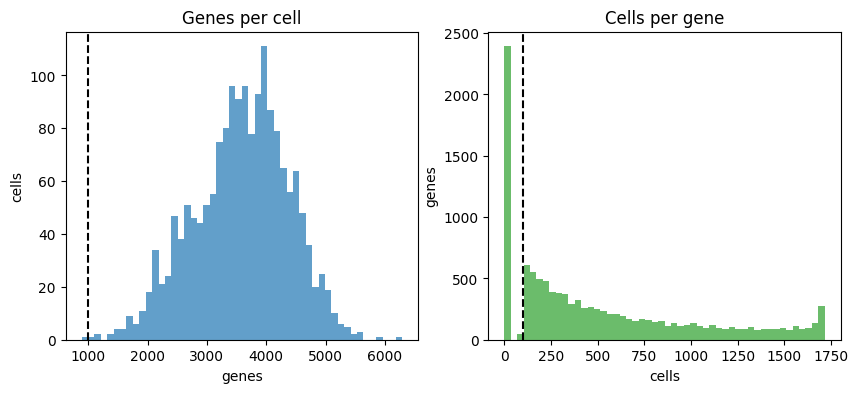

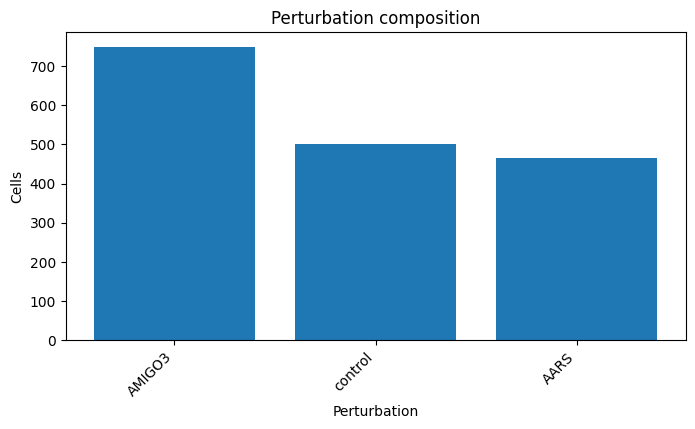

In [4]:
cx.pl.qc_summary(qc, min_genes=1000, min_cells_per_gene=100)
_ = cx.pl.qc_perturbation_counts(data=DATA_PATH, perturbation_column='perturbation', cell_mask=qc.cell_mask)

### A threshold that removes too much

crispyx warns when a filter drops more than half the data, usually a sign of a threshold meant for another dataset. The cell sets a deliberately strict cutoff, and captures the warning to print its message alone.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    _ = cx.pp.filter_cells(DATA_PATH, min_genes=4200)

for warning in caught:
    print(f'{warning.category.__name__}: {warning.message}')

[cx] pp.filter_cells: Done  384/1716 cells kept (22%)


Two questions QC of a screen also asks need guides and unassigned cells, which this dataset does not have: do the non-targeting guides agree with each other (`cx.pp.control_guide_correlation`, plotted by `cx.pl.control_guide_correlation`), and may the unassigned cells join the controls (`cx.pp.compare_controls`)? The [control-checks tutorial](control_checks.ipynb) runs both on a real screen.

## 2. Fewer cells, fewer counts

Two functions reduce a dataset along different axes, both streamed and both before normalisation:

| Function | Decides | Typical use |
|---|---|---|
| `cx.pp.subsample` | which cells stay: `n` or `frac` per stratum of `groupby`; with `unit='batch'`, whole batches are kept or dropped | cap every perturbation at the same number of cells |
| `cx.pp.downsample_counts` | how many counts stay in a cell: thinned to `counts_per_cell` without replacement | equalise sequencing depth between datasets |

In [6]:
# at most 200 cells per perturbation; a smaller group would be kept whole (drop_insufficient=False)
subsampled = cx.pp.subsample(
    filtered_path, n=200, groupby='perturbation', drop_insufficient=False, random_state=0,
    output_path=OUTPUT_DIR / 'subsampled.h5ad',
)
subsampled.obs.load()['perturbation'].value_counts()

[cx] pp.subsample: Done  600/1715 cells kept (35%) across 3 stratum/strata (unit='cell')


perturbation
AARS       200
AMIGO3     200
control    200
Name: count, dtype: int64

In [7]:
depth = np.asarray(qc.filtered.to_memory().X.sum(axis=1)).ravel()
thinned = cx.pp.downsample_counts(
    filtered_path, OUTPUT_DIR / 'downsampled.h5ad', counts_per_cell=int(np.median(depth)), random_state=0,
)
depth_after = np.asarray(thinned.to_memory().X.sum(axis=1)).ravel()
print(f'counts per cell, median and maximum: {np.median(depth):,.0f} and {depth.max():,.0f} '
      f'-> {np.median(depth_after):,.0f} and {depth_after.max():,.0f}')

[cx] pp.downsample_counts: Saving → tutorial_outputs/basics_qc/downsampled.h5ad
[cx] pp.downsample_counts: Done  857/1715 cells thinned to <= 14514 counts
counts per cell, median and maximum: 14,514 and 44,938 -> 14,514 and 14,514


## 3. Normalisation

`cx.pp.normalize_total_log1p` is `scanpy.pp.normalize_total` followed by `scanpy.pp.log1p`, a block of cells at a time. The counts file stays as it is: count models (the NB-GLM in the next notebook) read it, while rank and mean tests read the normalised file.

In [8]:
normalised = cx.pp.normalize_total_log1p(filtered_path, OUTPUT_DIR / 'log1p.h5ad', target_sum=1e4)
print(normalised.shape)

[cx] pp.normalize_total_log1p: Saving → tutorial_outputs/basics_qc/log1p.h5ad
[cx] pp.normalize_total_log1p: Done  1715 cells × 9238 genes
(1715, 9238)


## 4. Variable genes, PCA, neighbours, UMAP

- **Highly variable genes.** `cx.pp.highly_variable_genes` writes `var['highly_variable']`. In a screen it uses the control cells by default (`cell_mask='control'`), so that the genes chosen describe cell state rather than perturbation effects; `cell_mask=None` uses every cell. `flavor='mean_dispersion'` suits log-normalised data, `'seurat_v3'` raw counts.
- **PCA.** `cx.pp.pca` reads the cells twice (fit, then project) and writes `X_pca` a chunk at a time. It uses the highly variable genes when they are marked, and picks the exact `covariance` method whenever it fits in memory.
- **Neighbours and UMAP.** `cx.pp.neighbors` and `cx.tl.umap` work on the embedding, not the matrix.

Results are written into the normalised file. The peak memory of each step is in [Working with large data](../large_data.rst).

In [9]:
cx.pp.highly_variable_genes(normalised, flavor='mean_dispersion', n_top_genes=2000,
                            perturbation_column='perturbation', control_label='control')
cx.pp.pca(normalised, n_comps=20)
cx.pp.neighbors(normalised, n_neighbors=10, show_progress=False)
cx.tl.umap(normalised, min_dist=0.5, spread=1.0)

pca = normalised.uns['pca'].load()
print(f"PCA: {pca['method']} on {int(normalised.var['highly_variable'].sum()):,} genes; "
      f"variance explained by the first five components: {pca['variance_ratio'][:5].round(3)}")
print('written to the file:', sorted(normalised.obsm.keys()), sorted(normalised.obsp.keys()))

[cx] pp.highly_variable_genes: Reading tutorial_outputs/basics_qc/log1p.h5ad
[cx] pp.highly_variable_genes: Done  2000/9238 genes marked highly variable
PCA: covariance on 2,000 genes; variance explained by the first five components: [0.051 0.028 0.023 0.014 0.012]
written to the file: ['X_pca', 'X_umap'] ['connectivities', 'distances']


The plotting functions follow Scanpy's and read only what they draw.

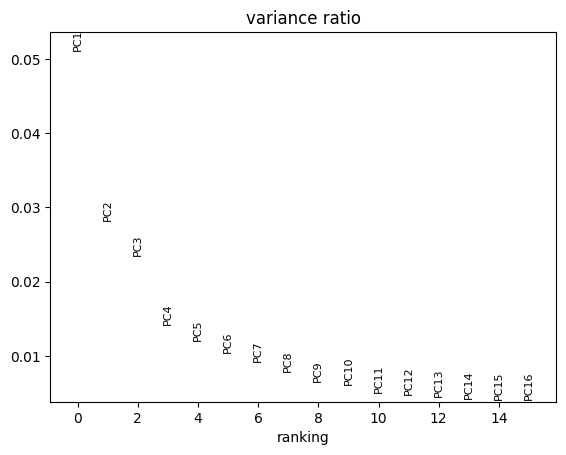

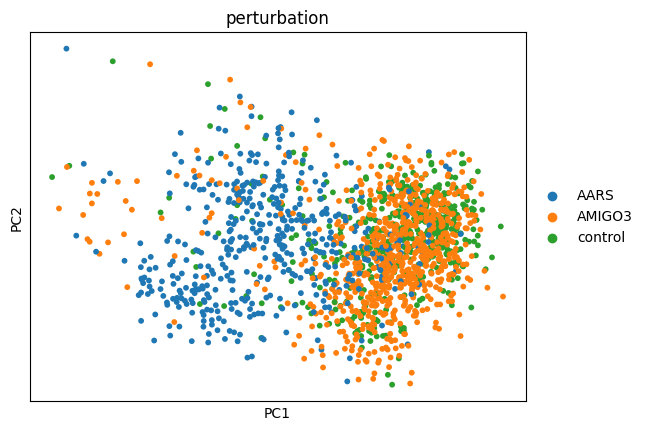

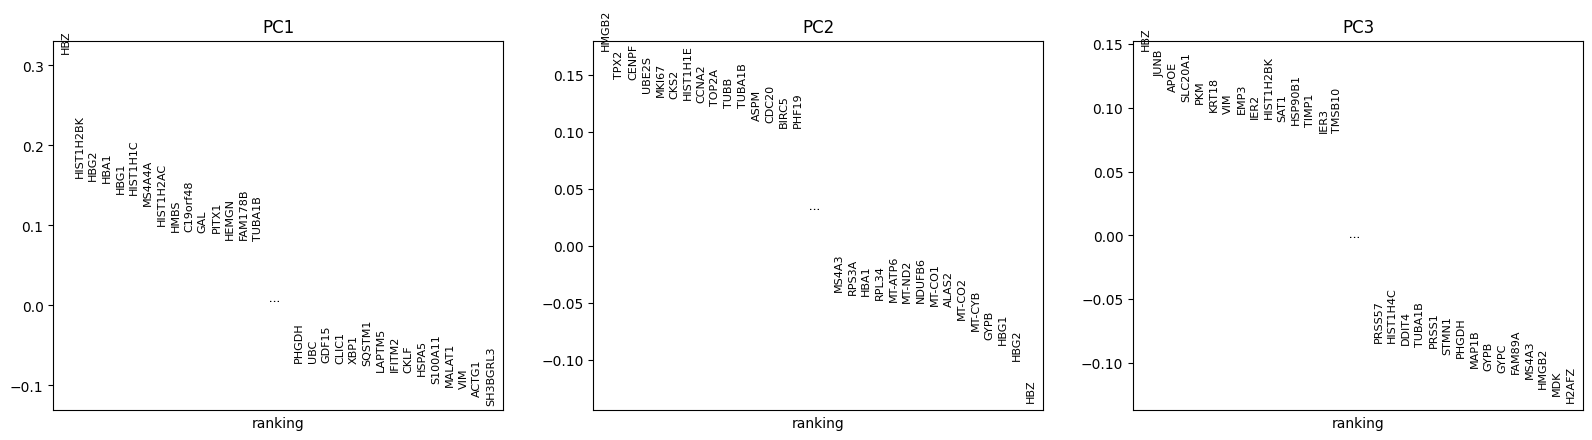

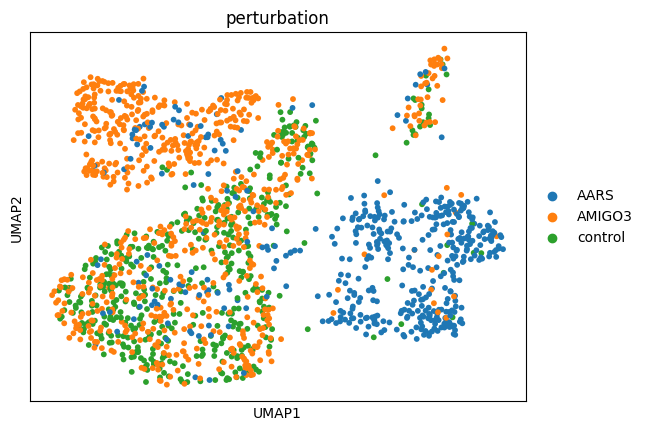

In [10]:
cx.pl.pca_variance_ratio(normalised, n_pcs=15)
cx.pl.pca(normalised, color='perturbation', components='1,2')
cx.pl.pca_loadings(normalised, components=[1, 2, 3])
cx.pl.umap(normalised, color='perturbation')

## Functions in this notebook

| Function | What it does | Where |
|---|---|---|
| `cx.pp.filter_cells`, `cx.pp.filter_perturbations`, `cx.pp.filter_genes` | one QC filter each, as a mask | section 1 |
| `cx.pp.qc_summary`, `cx.quality_control_summary` | the three filters in one call, writing the filtered file | 1 |
| `cx.pl.qc_summary`, `cx.pl.qc_perturbation_counts` | QC distributions and cells per perturbation | 1 |
| `cx.pp.compare_controls`, `cx.pp.control_guide_correlation`, `cx.pl.control_guide_correlation` | whether the controls behave alike | [control-checks tutorial](control_checks.ipynb) |
| `cx.pp.subsample` | stratified or cluster sampling of cells | 2 |
| `cx.pp.downsample_counts` | thin each cell's counts to a target | 2 |
| `cx.pp.normalize_total_log1p` | total-count normalisation and log1p | 3 |
| `cx.pp.highly_variable_genes` | variable genes, from the controls by default | 4 |
| `cx.pp.pca`, `cx.pp.neighbors`, `cx.tl.umap` | embedding and neighbour graph, written to the file | 4 |
| `cx.pl.pca`, `cx.pl.pca_variance_ratio`, `cx.pl.pca_loadings`, `cx.pl.umap` | plots of the embedding | 4 |

Next: [Effects and differential expression](basics_3_effects_tests.ipynb). More on each step: [Quality control and preprocessing](../quality_control.rst).